In [1]:
# Setup
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import torch
from timestral import TimestralForecaster

MODEL_ID = "mistralai/Timestral-209M"
# MODEL_ID = "mistralai/Timestral-123M"
# MODEL_ID = "mistralai/Timestral-28M"
# MODEL_ID = "mistralai/Timestral-5M"

device = "cuda" if torch.cuda.is_available() else "cpu"
pipeline = TimestralForecaster.from_pretrained(MODEL_ID, device=device)

MODEL_LABEL = MODEL_ID.split("/")[1]
MAX_CONTEXT = pipeline.max_context
MAX_HORIZON = 1024
print(f"Loaded {MODEL_LABEL} on {device}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded Timestral-209M on cpu


In [2]:
# Load data
import json

DATA_FILE = "tep_sp_clean.h5"


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


groups = {}
with h5py.File(DATA_FILE, "r") as f:
    time_h = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "dist", "sp"]:
        groups[key] = (f[key][()], read_names(f[key]))
    if "y" in f:   # true valve positions
        groups["valve"] = (f["y"][:, 38:50], read_names(f["y"])[38:50])
    config = json.loads(f.attrs["config"])
SAMPLE_MIN = config["record_every"] / 60   # sampling interval (min)

nominal = {int(k): v for k, v in config["setpoints"].items()}
CHANGED = sorted({k for k, _, _ in config["setpoint_schedule"]})   # set points changed in this run
t_test = config.get("t_test")                                    # start of the test changes (h)

sp = groups["sp"][0]
off = {k: np.abs(sp[:, k - 1] - nominal[k]) > 1e-9 for k in CHANGED}
sp_change = np.zeros(len(time_h), dtype=int)
for k in reversed(CHANGED):
    sp_change[off[k]] = k

data = {"time_h": time_h, "sp_change": sp_change}
COLUMNS, LABELS = {}, {}
for group, (values, labels) in groups.items():
    COLUMNS[group] = [f"{group}_{i}" for i in range(1, values.shape[1] + 1)]
    for col, v, label in zip(COLUMNS[group], values.T, labels):
        data[col] = v
        LABELS[col] = label

df = pd.DataFrame(data)
df.insert(0, "item_id", "tep")
df.insert(1, "timestamp", pd.date_range("2026-01-01", periods=len(df), freq=f"{config['record_every']}s"))

TARGET_COLUMNS = COLUMNS["xmeas"] + COLUMNS["xmv"]
print(f"{len(df)} samples ({time_h[-1]:.0f} h), {len(TARGET_COLUMNS)} targets, covariate groups: "
      + ", ".join(f"{g} ({len(COLUMNS[g])})" for g in COLUMNS if g not in ["xmeas", "xmv"]))
print(f"changed set points: {CHANGED}, test part from {t_test} h")
df.head()

5750 samples (575 h), 53 targets, covariate groups: dist (12), sp (20), valve (12)
changed set points: [11, 18, 19, 20], test part from 490.0 h


,item_id,timestamp,time_h,sp_change,xmeas_1,xmeas_2,xmeas_3,xmeas_4,xmeas_5,xmeas_6,...,valve_3,valve_4,valve_5,valve_6,valve_7,valve_8,valve_9,valve_10,valve_11,valve_12
0,tep,2026-01-01 00:00:00,0.1,0,0.250523,3664.030181,4509.296443,9.347701,26.902001,42.338460,...,24.643711,61.301653,22.211646,40.063982,38.100120,46.533724,47.446040,41.105582,18.115263,50.0
1,tep,2026-01-01 00:06:00,0.2,0,0.250562,3664.027024,4509.264005,9.347715,26.902008,42.338429,...,24.647590,61.301744,22.211978,40.063198,38.100832,46.534280,47.445907,41.105333,18.114816,50.0
2,tep,2026-01-01 00:12:00,0.3,0,0.250566,3664.018255,4509.259890,9.347742,26.902003,42.338418,...,24.647951,61.301922,22.212287,40.063880,38.100850,46.534642,47.445855,41.105467,18.114489,50.0
3,tep,2026-01-01 00:18:00,0.4,0,0.250570,3664.017070,4509.257609,9.347764,26.902001,42.338456,...,24.648343,61.302064,22.212388,40.063853,38.100668,46.534565,47.445918,41.105652,18.114611,50.0
4,tep,2026-01-01 00:24:00,0.5,0,0.250557,3664.017551,4509.256008,9.347785,26.902002,42.338475,...,24.647110,61.302202,22.212502,40.063654,38.100651,46.534499,47.445995,41.105687,18.114724,50.0


In [3]:
# Pick a forecast window
events = []   # (start index, end index, set point, new value)
for k in CHANGED:
    on = off[k]
    for i in range(len(on)):
        if on[i] and (i == 0 or not on[i - 1]):
            start = i
        if on[i] and (i == len(on) - 1 or not on[i + 1]):
            events.append((start, i, k, sp[start, k - 1]))
events.sort()

for n, (s, e, k, v) in enumerate(events):
    part = "test " if t_test is not None and time_h[s] >= t_test else "train"
    print(f"{n:2d}  {part}  SP {k:2d}  samples {s:4d}-{e:4d}  ({time_h[s]:5.1f}-{time_h[e]:5.1f} h)  "
          f"{nominal[k]:.4g} -> {v:.4g} ({100 * (v - nominal[k]) / nominal[k]:+.1f}%)  {LABELS[f'sp_{k}']}")

EVENT_INDEX = 23
START = None
BUFFER = 20
HORIZON = 200
PLOT_LEAD_IN = 200

event_start, event_end, event_sp, event_value = events[EVENT_INDEX]
if START is None:
    SPLIT = max(event_start - BUFFER, 0)
    default_horizon = event_end - SPLIT + 100
else:
    SPLIT = START
    default_horizon = MAX_HORIZON
HORIZON = min(HORIZON or default_horizon, MAX_HORIZON, len(df) - SPLIT)
context_used = min(SPLIT, MAX_CONTEXT)

window_changes = [k for k in CHANGED if off[k][SPLIT:SPLIT + HORIZON].any()]
print(f"\nForecast from sample {SPLIT} ({time_h[SPLIT]:.1f} h), horizon {HORIZON} samples ({HORIZON * SAMPLE_MIN / 60:.1f} h)")
print(f"Context: {SPLIT} samples available, {context_used} used (model max {MAX_CONTEXT})")
print(f"Set points off nominal in the forecast window: {window_changes if window_changes else 'none'}")

 0  train  SP 11  samples   99- 198  ( 10.0- 19.9 h)  22.95 -> 22.75 (-0.9%)  Stripper underflow (m3/h)
 1  train  SP 20  samples  299- 398  ( 30.0- 39.9 h)  0.8357 -> 0.7757 (-7.2%)  Product E (mol%)
 2  train  SP 18  samples  499- 598  ( 50.0- 59.9 h)  120.4 -> 120 (-0.3%)  Reactor temperature (C)
 3  train  SP 19  samples  699- 798  ( 70.0- 79.9 h)  13.82 -> 11.82 (-14.5%)  Purge B (mol%)
 4  train  SP 19  samples  899- 998  ( 90.0- 99.9 h)  13.82 -> 15.82 (+14.5%)  Purge B (mol%)
 5  train  SP 20  samples 1099-1198  (110.0-119.9 h)  0.8357 -> 0.7157 (-14.4%)  Product E (mol%)
 6  train  SP 20  samples 1299-1398  (130.0-139.9 h)  0.8357 -> 0.9557 (+14.4%)  Product E (mol%)
 7  train  SP 19  samples 1499-1598  (150.0-159.9 h)  13.82 -> 12.82 (-7.2%)  Purge B (mol%)
 8  train  SP 20  samples 1699-1798  (170.0-179.9 h)  0.8357 -> 0.8957 (+7.2%)  Product E (mol%)
 9  train  SP 18  samples 1899-1998  (190.0-199.9 h)  120.4 -> 118.9 (-1.2%)  Reactor temperature (C)
10  train  SP 11  sampl

In [4]:
# Covariates
USE_DIST = False                 # disturbance signals (12)
USE_SP = True                    # changed set points (11)
USE_VALVE = False                # true valve positions (12)
DROPPED = []
PAST_ONLY = []
COVARIATES_KNOWN_FUTURE = True

COVARIATE_COLUMNS = []
for group, use in [("dist", USE_DIST), ("sp", USE_SP), ("valve", USE_VALVE)]:
    if use and group in COLUMNS:
        COVARIATE_COLUMNS += [f"sp_{k}" for k in CHANGED] if group == "sp" else COLUMNS[group]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in DROPPED]

context_df = df.iloc[SPLIT - context_used:SPLIT]
truth_df = df.iloc[SPLIT:SPLIT + HORIZON]

window_df = pd.concat([context_df, truth_df])
constant = [c for c in COVARIATE_COLUMNS if window_df[c].nunique() == 1]
COVARIATE_COLUMNS = [c for c in COVARIATE_COLUMNS if c not in constant]

FUTURE_COV = [c for c in COVARIATE_COLUMNS if COVARIATES_KNOWN_FUTURE and c not in PAST_ONLY]
PAST_ONLY_COV = [c for c in COVARIATE_COLUMNS if c not in FUTURE_COV]

print(f"targets ({len(TARGET_COLUMNS)}): {', '.join(TARGET_COLUMNS)}")
print(f"past + future covariates ({len(FUTURE_COV)}): {', '.join(FUTURE_COV) or '-'}")
print(f"past-only covariates ({len(PAST_ONLY_COV)}): {', '.join(PAST_ONLY_COV) or '-'}")
if constant:
    print(f"left out, constant over the window ({len(constant)}): {', '.join(constant)}")

targets (53): xmeas_1, xmeas_2, xmeas_3, xmeas_4, xmeas_5, xmeas_6, xmeas_7, xmeas_8, xmeas_9, xmeas_10, xmeas_11, xmeas_12, xmeas_13, xmeas_14, xmeas_15, xmeas_16, xmeas_17, xmeas_18, xmeas_19, xmeas_20, xmeas_21, xmeas_22, xmeas_23, xmeas_24, xmeas_25, xmeas_26, xmeas_27, xmeas_28, xmeas_29, xmeas_30, xmeas_31, xmeas_32, xmeas_33, xmeas_34, xmeas_35, xmeas_36, xmeas_37, xmeas_38, xmeas_39, xmeas_40, xmeas_41, xmv_1, xmv_2, xmv_3, xmv_4, xmv_5, xmv_6, xmv_7, xmv_8, xmv_9, xmv_10, xmv_11, xmv_12
past + future covariates (4): sp_11, sp_18, sp_19, sp_20
past-only covariates (0): -


In [5]:
# Run Timestral
QUANTILES = [0.1, 0.5, 0.9]

past_cov = None
if PAST_ONLY_COV:
    past_cov = context_df[PAST_ONLY_COV].to_numpy(dtype=np.float32).T[None]    # (1, covariates, context)
known_cov = None
if FUTURE_COV:
    known_cov = window_df[FUTURE_COV].to_numpy(dtype=np.float32).T[None]       # (1, covariates, context + horizon)

out = pipeline.forecast(
    context_df[TARGET_COLUMNS].to_numpy(dtype=np.float32).T[None],             # (1, targets, context)
    prediction_length=HORIZON,
    past_covariates=past_cov,
    known_covariates=known_cov,
)
quantiles = out.quantiles[0].cpu().numpy()   # (targets, horizon, 21) levels 0.01 .. 0.99
median = pipeline.quantile_levels.index(0.5)

pred_parts = []
for v, col in enumerate(TARGET_COLUMNS):
    part = pd.DataFrame({
        "timestamp": truth_df["timestamp"].values,
        "time_h": truth_df["time_h"].values,
        "target_name": col,
        "predictions": quantiles[v, :, median],
    })
    for q in QUANTILES:
        part[str(q)] = quantiles[v, :, pipeline.quantile_levels.index(q)]
    pred_parts.append(part)

pred_df = pd.concat(pred_parts, ignore_index=True)
pred_df.head()

,timestamp,time_h,target_name,predictions,0.1,0.5,0.9
0,2026-01-20 11:54:00,468.0,xmeas_1,0.250144,0.250064,0.250144,0.250221
1,2026-01-20 12:00:00,468.1,xmeas_1,0.249544,0.249462,0.249544,0.249627
2,2026-01-20 12:06:00,468.2,xmeas_1,0.248991,0.248902,0.248991,0.249081
3,2026-01-20 12:12:00,468.3,xmeas_1,0.248450,0.248353,0.248450,0.248549
4,2026-01-20 12:18:00,468.4,xmeas_1,0.248010,0.247903,0.248010,0.248113


In [6]:
# Accuracy
normal_context = context_df[context_df["sp_change"] == 0]
in_fault = truth_df["sp_change"].to_numpy() != 0
last_value = context_df.iloc[-1]

rows = []
for col in TARGET_COLUMNS:
    pred = pred_df.loc[pred_df["target_name"] == col, "predictions"].to_numpy()
    actual = truth_df[col].to_numpy()
    scale = normal_context[col].std()
    if scale == 0:
        scale = np.nan
    err = pd.Series(np.abs(pred - actual) / scale)
    base_err = pd.Series(np.abs(last_value[col] - actual) / scale)
    rows.append({
        "variable": col,
        "description": LABELS[col],
        "MAE": np.abs(pred - actual).mean(),
        "scaled MAE (nominal)": err[~in_fault].mean(),
        "scaled MAE (off nominal)": err[in_fault].mean(),
        "scaled MAE (all)": err.mean(),
        "baseline (nominal)": base_err[~in_fault].mean(),
        "baseline (off nominal)": base_err[in_fault].mean(),
        "baseline (all)": base_err.mean(),
    })
accuracy = pd.DataFrame(rows).set_index("variable")

phases = ["nominal", "off nominal", "all"]
summary = pd.DataFrame({
    MODEL_LABEL: [accuracy[f"scaled MAE ({p})"].mean() for p in phases],
    "last-value baseline": [accuracy[f"baseline ({p})"].mean() for p in phases],
    "samples": [(~in_fault).sum(), in_fault.sum(), len(in_fault)],
}, index=phases)
print(f"Mean scaled MAE over {accuracy['scaled MAE (all)'].notna().sum()} scored targets")
print(summary.round(3).to_string())
beats = (accuracy["scaled MAE (all)"] < accuracy["baseline (all)"]).sum()
print(f"{MODEL_LABEL} beats the baseline on {beats} / {accuracy['scaled MAE (all)'].notna().sum()} targets")
accuracy.sort_values("scaled MAE (all)", ascending=False).round(4)

Mean scaled MAE over 52 scored targets
             Timestral-209M  last-value baseline  samples
nominal               0.089                0.120      100
off nominal           0.260                0.208      100
all                   0.175                0.164      200
Timestral-209M beats the baseline on 30 / 52 targets


,description,MAE,scaled MAE (nominal),scaled MAE (off nominal),scaled MAE (all),baseline (nominal),baseline (off nominal),baseline (all)
variable,,,,,,,,
xmv_8,Stripper product flow,0.0800,0.0803,1.0284,0.5544,0.2432,0.4750,0.3591
xmeas_15,Stripper level (%),0.0345,0.0799,1.0275,0.5537,0.2432,0.4750,0.3591
xmeas_28,Reactor feed F (mol%),0.0253,0.4132,0.4273,0.4202,0.1589,0.1024,0.1307
xmeas_34,Purge F (mol%),0.0302,0.3700,0.3623,0.3661,0.1599,0.0998,0.1299
xmv_7,Separator underflow,0.0820,0.1588,0.5665,0.3627,0.0633,0.1075,0.0854
xmeas_12,Separator level (%),0.0270,0.1576,0.5443,0.3509,0.0633,0.1075,0.0854
xmeas_2,D feed (kg/h),3.3651,0.0872,0.5284,0.3078,0.1158,0.2112,0.1635
xmv_1,D feed flow,0.0578,0.0871,0.5271,0.3071,0.1158,0.2112,0.1635
xmeas_14,Separator underflow (m3/h),0.0446,0.1058,0.4668,0.2863,0.0762,0.1331,0.1046


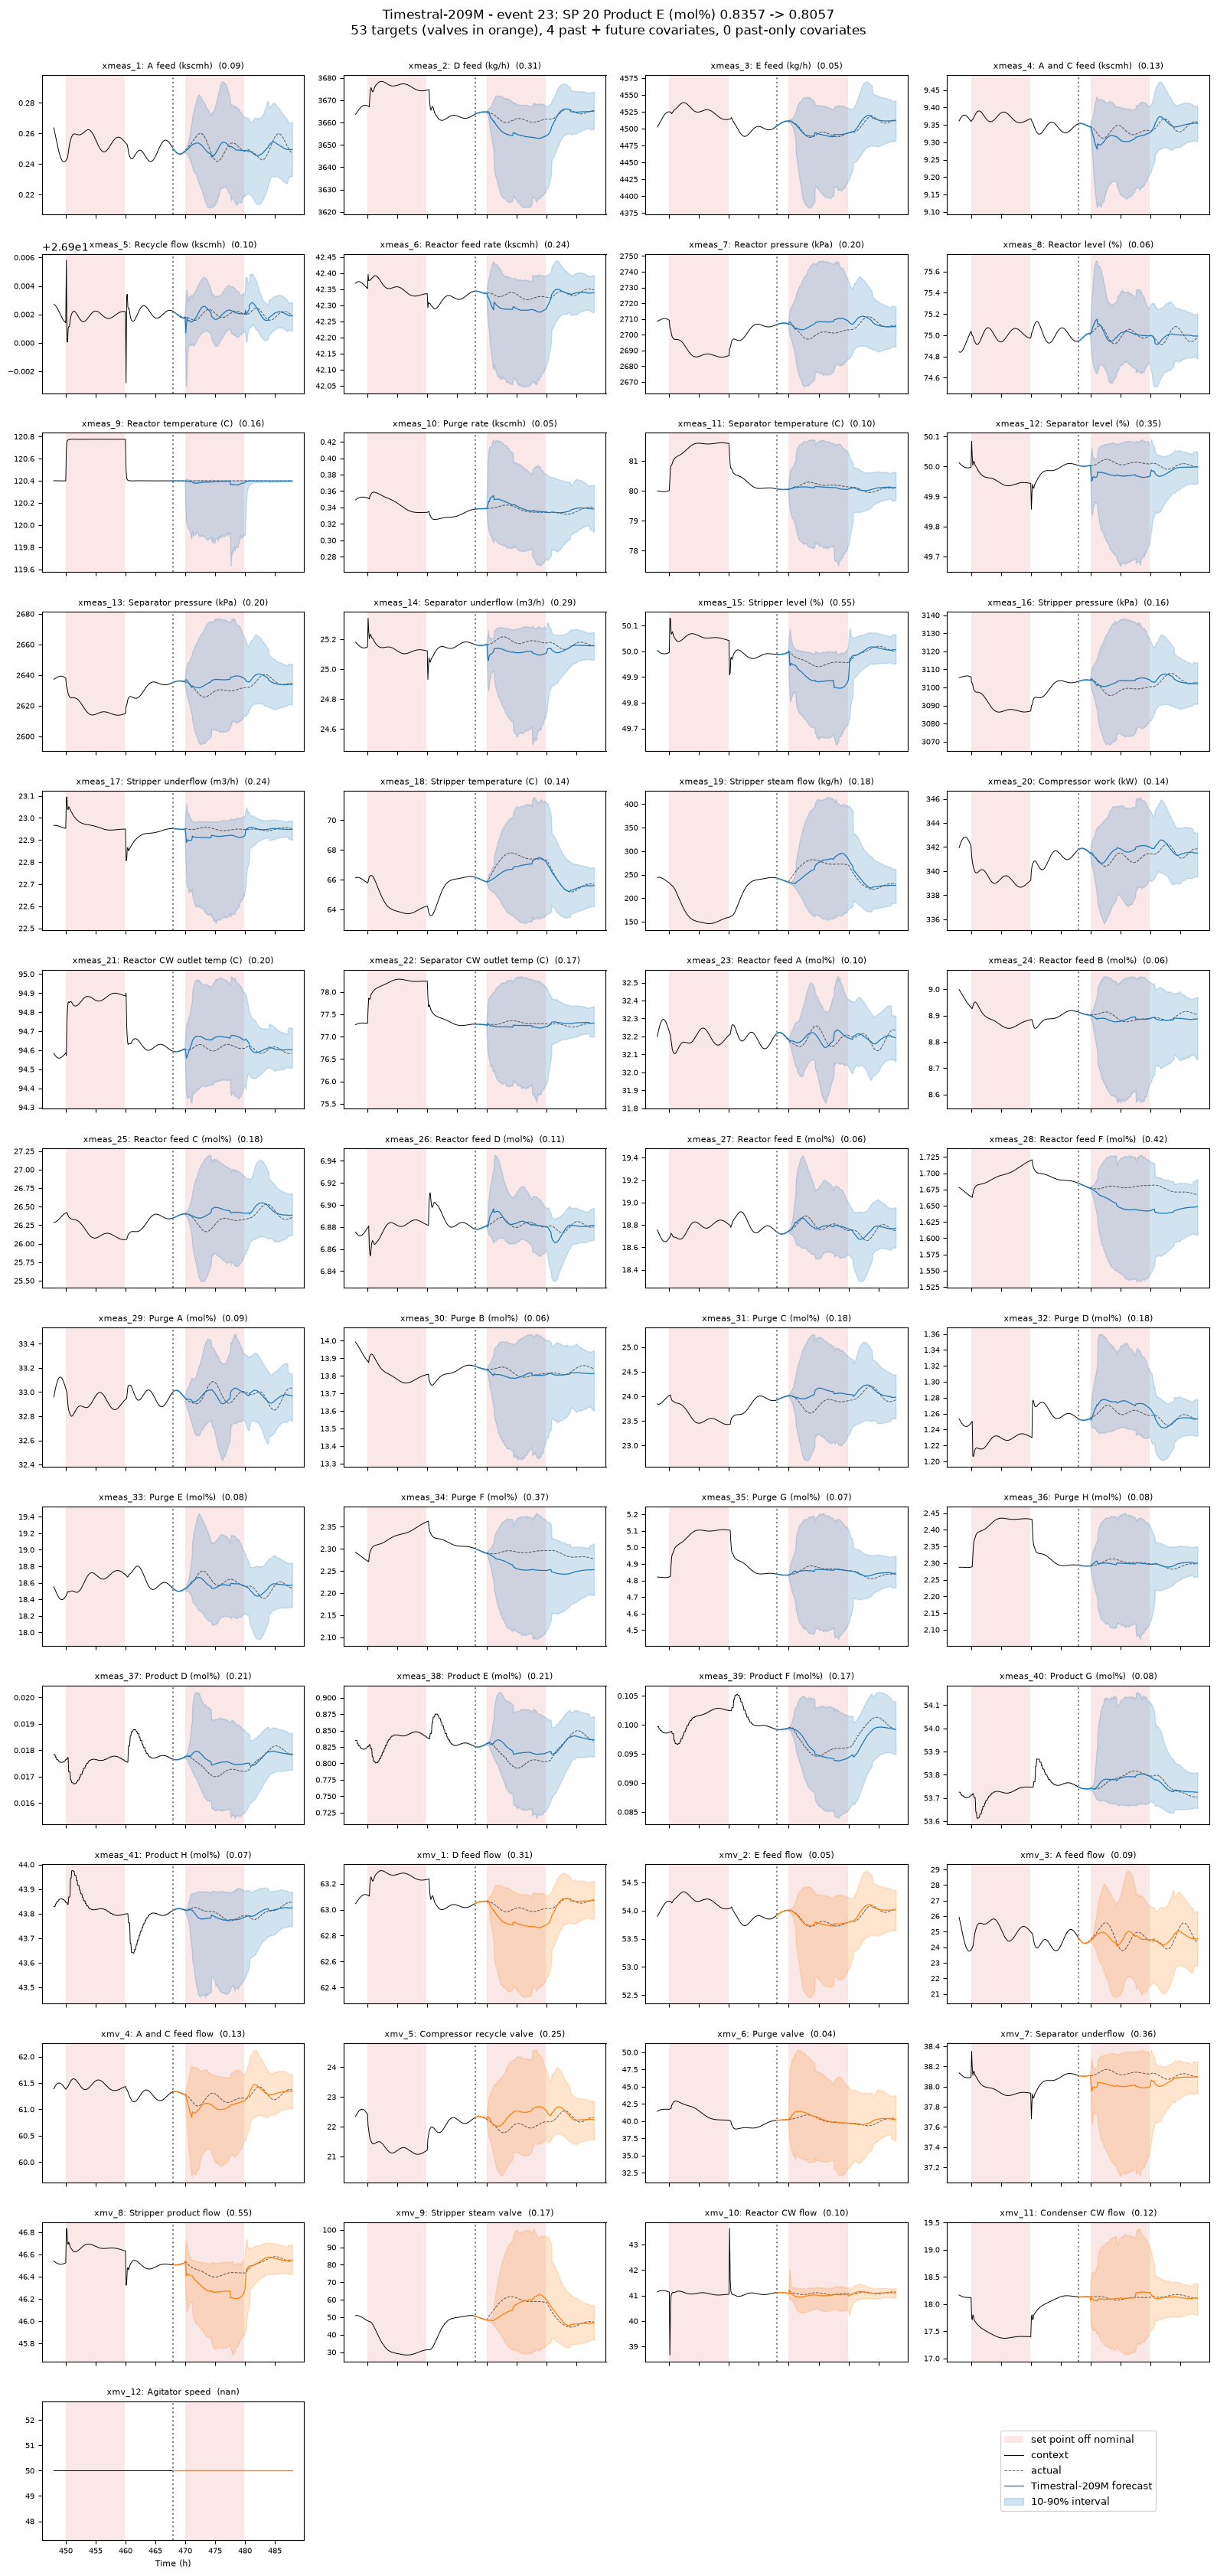

In [7]:
# Plot every target
lead = context_df.iloc[-PLOT_LEAD_IN:]
shown = pd.concat([lead, truth_df])

n_rows = -(-(len(TARGET_COLUMNS) + 1) // 4)
fig, axes = plt.subplots(n_rows, 4, figsize=(16, 2.4 * n_rows), sharex=True)
for ax, col in zip(axes.ravel(), TARGET_COLUMNS):
    sub = pred_df[pred_df["target_name"] == col]
    color = "tab:orange" if col.startswith("xmv") else "tab:blue"
    ax.fill_between(shown["time_h"], 0, 1, where=shown["sp_change"] != 0, color="tab:red", alpha=0.1,
                    transform=ax.get_xaxis_transform(), step="post", lw=0, label="set point off nominal")
    ax.plot(lead["time_h"], lead[col], color="black", lw=0.7, label="context")
    ax.plot(truth_df["time_h"], truth_df[col], color="black", lw=0.7, ls="--", alpha=0.6, label="actual")
    ax.plot(sub["time_h"], sub["predictions"], color=color, lw=0.9, label=f"{MODEL_LABEL} forecast")
    ax.fill_between(sub["time_h"], sub["0.1"], sub["0.9"], color=color, alpha=0.2, label="10-90% interval")
    ax.axvline(truth_df["time_h"].iloc[0], color="gray", ls=":")
    ax.set_title(f"{col}: {LABELS[col]}  ({accuracy.loc[col, 'scaled MAE (all)']:.2f})", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(TARGET_COLUMNS):]:
    ax.axis("off")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
axes.ravel()[-1].legend(handles, labels, loc="center", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Time (h)", fontsize=8)
fig.suptitle(f"{MODEL_LABEL} - event {EVENT_INDEX}: SP {event_sp} {LABELS[f'sp_{event_sp}']} "
             f"{nominal[event_sp]:.4g} -> {event_value:.4g}\n"
             f"{len(TARGET_COLUMNS)} targets (valves in orange), {len(FUTURE_COV)} past + future covariates, "
             f"{len(PAST_ONLY_COV)} past-only covariates", y=1.0)
fig.tight_layout()

In [8]:
# Save results
import os

RESULTS_FILE = "Results/setpointforecast_timestral.h5"
ACCURACY_COLUMNS = ["MAE", "scaled MAE (nominal)", "scaled MAE (off nominal)", "scaled MAE (all)",
                    "baseline (nominal)", "baseline (off nominal)", "baseline (all)"]

os.makedirs("Results", exist_ok=True)
with h5py.File(RESULTS_FILE, "w") as f:
    f.attrs["model"] = MODEL_LABEL
    f.attrs["settings"] = json.dumps({
        "data_file": DATA_FILE,
        "event_index": EVENT_INDEX,
        "split": int(SPLIT),
        "horizon": int(HORIZON),
        "future_covariates": FUTURE_COV,
        "past_only_covariates": PAST_ONLY_COV,
    })

    # Accuracy table
    f.create_dataset("variable", data=list(accuracy.index))
    f.create_dataset("description", data=list(accuracy["description"]))
    for name in ACCURACY_COLUMNS:
        f.create_dataset(name, data=accuracy[name].to_numpy())

    # Forecasts, actual values and the end of the context
    f.create_dataset("time_h", data=truth_df["time_h"].to_numpy())
    f.create_dataset("off_nominal", data=truth_df["sp_change"].to_numpy() != 0)
    f.create_dataset("context_time_h", data=lead["time_h"].to_numpy())
    for col in TARGET_COLUMNS:
        sub = pred_df[pred_df["target_name"] == col]
        f.create_dataset(f"forecast/{col}", data=sub["predictions"].to_numpy())
        f.create_dataset(f"lower/{col}", data=sub["0.1"].to_numpy())
        f.create_dataset(f"upper/{col}", data=sub["0.9"].to_numpy())
        f.create_dataset(f"actual/{col}", data=truth_df[col].to_numpy())
        f.create_dataset(f"context/{col}", data=lead[col].to_numpy())
print(f"Saved {MODEL_LABEL} results to {RESULTS_FILE}")


Saved Timestral-209M results to Results/setpointforecast_timestral.h5
